In [46]:
!pip install kagglehub

In [47]:
import kagglehub
path = kagglehub.dataset_download('jacopoferretti/bbc-articles-dataset')


Using Colab cache for faster access to the 'bbc-articles-dataset' dataset.


In [48]:
import os
os.listdir(path)

['bbc_news_text_complexity_summarization.csv', 'archive (2)', 'archive']

In [49]:
import pandas as pd
data = pd.read_csv(path + '/bbc_news_text_complexity_summarization.csv' )

In [50]:
data.iloc[1000:1600]


,text,labels,no_sentences,Flesch Reading Ease Score,Dale-Chall Readability Score,text_rank_summary,lsa_summary
1000,UK troops on Ivory Coast standby\n\nDowning St...,politics,10,57.50,9.81,They are ready to fly out and secure the route...,Downing Street has confirmed British troops ar...
1001,Blair told to double overseas aid\n\nTony Blai...,politics,27,63.59,9.41,The call comes as the prime minister prepares ...,Some 45 million children will die needlessly b...
1002,Peace demo appeal rejected\n\nPeace protestors...,politics,14,54.15,9.12,The demonstrators appealed against a finding b...,They had appealed against a High Court decisio...
1003,"Retirement age could be scrapped\n\nThe ""myth ...",politics,11,50.06,9.43,"The ""myth that ageing is a barrier"" to contrib...",All three parties have been wooing older voter...
1004,Jowell rejects 'Las Vegas' jibe\n\nThe Secreta...,politics,15,70.23,9.37,And over all of it hangs the shadow of the men...,Meanwhile Labour backbencher Stephen Pound lab...
...,...,...,...,...,...,...,...
1595,"Worcester v Sale (Fri)\n\nSixways\n\nFriday, 2...",sport,7,63.29,14.20,"Friday, 25 February They make just one change,...","They make just one change, with Tim Collier re..."
1596,Robinson answers critics\n\nEngland captain Ja...,sport,19,81.22,7.32,"""But if we can under-perform and lose by only ...",England captain Jason Robinson has rubbished s...
1597,Sella wants Michalak recall\n\nFormer France c...,sport,25,79.50,7.44,The 22-year-old Michalak has spent much of the...,Former France centre Philippe Sella believes c...
1598,Umaga ready for Lions\n\nAll Blacks captain Ta...,sport,25,77.98,7.85,The 31-year-old admitted interest in the Lions...,All Blacks captain Tama Umaga has warned the B...


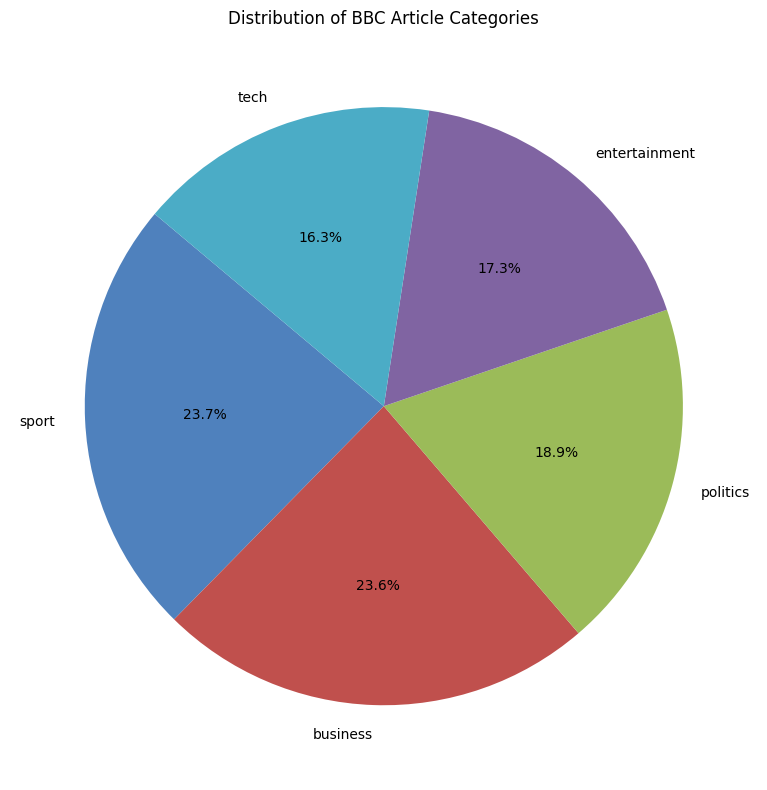

In [51]:
import matplotlib.pyplot as plt

# Calculate category frequencies
label_counts = data['labels'].value_counts()

# Set up and render the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    label_counts,
    labels=label_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4F81BD', '#C0504D', '#9BBB59', '#8064A2', '#4BACC6']
)
plt.title('Distribution of BBC Article Categories')
plt.tight_layout()
plt.show()

In [52]:
y = data['labels']
x= data['text']

In [53]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42 ,    stratify=y)

In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer
t = TfidfVectorizer(
    max_features=5000,
    stop_words='english'
)
x_train = t.fit_transform(x_train)
x_test = t.transform(x_test)

In [55]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(x_train, y_train)

LogisticRegression()

In [56]:
from sklearn.metrics import accuracy_score, classification_report
y_pred = model.predict(x_test)

# 9. Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9882629107981221
               precision    recall  f1-score   support

     business       1.00      0.97      0.98       101
entertainment       0.99      1.00      0.99        74
     politics       0.99      0.99      0.99        81
        sport       1.00      1.00      1.00       101
         tech       0.96      0.99      0.97        69

     accuracy                           0.99       426
    macro avg       0.99      0.99      0.99       426
 weighted avg       0.99      0.99      0.99       426



test ::

In [60]:
news = [
    "Artificial intelligence is changing computer technology",
    "The football team won the world championship",
]
newsf = t.transform(news)
prediction = model.predict(newsf)
print(prediction)

['tech' 'sport']
